In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("heart.csv")

In [3]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
df.describe

<bound method NDFrame.describe of      Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
0     40   M           ATA        140          289          0     Normal   
1     49   F           NAP        160          180          0     Normal   
2     37   M           ATA        130          283          0         ST   
3     48   F           ASY        138          214          0     Normal   
4     54   M           NAP        150          195          0     Normal   
..   ...  ..           ...        ...          ...        ...        ...   
913   45   M            TA        110          264          0     Normal   
914   68   M           ASY        144          193          1     Normal   
915   57   M           ASY        130          131          0     Normal   
916   57   F           ATA        130          236          0        LVH   
917   38   M           NAP        138          175          0     Normal   

     MaxHR ExerciseAngina  Oldpeak ST_Slope  HeartDis

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [6]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [7]:
df.drop_duplicates(inplace=True)

<Axes: xlabel='Age', ylabel='Count'>

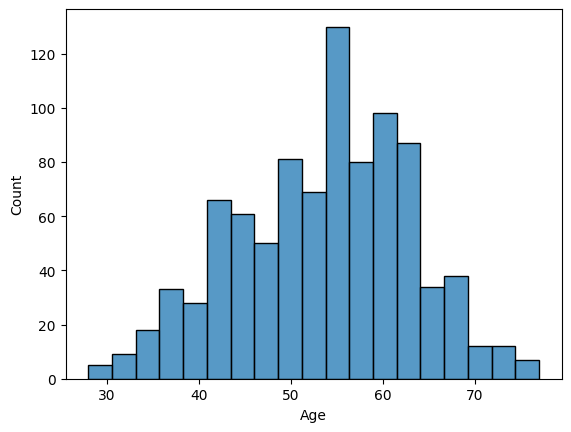

In [8]:
sns.histplot(data=df, x='Age')

<Axes: xlabel='Sex', ylabel='Count'>

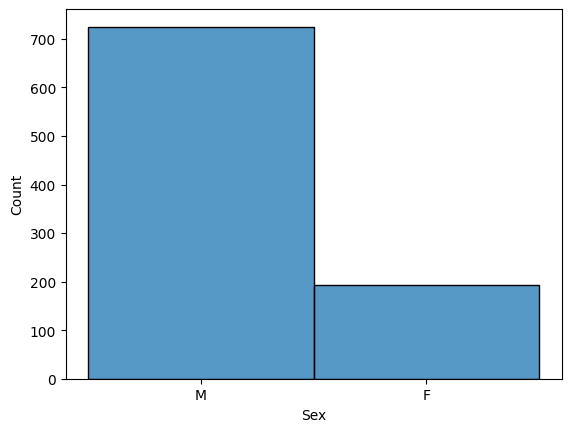

In [9]:
sns.histplot(data=df, x='Sex')

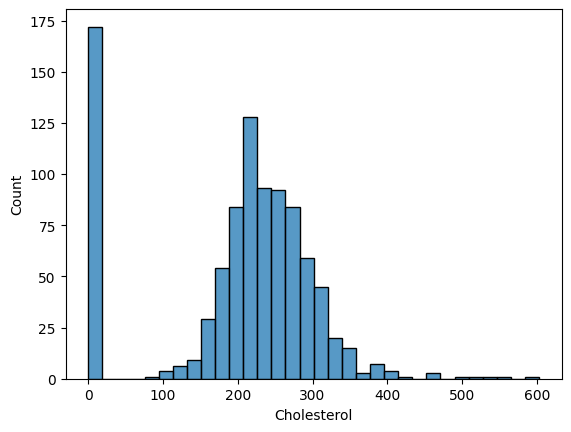

In [10]:
sns.histplot(data=df, x='Cholesterol')
plt.show()

<Axes: xlabel='RestingBP', ylabel='Count'>

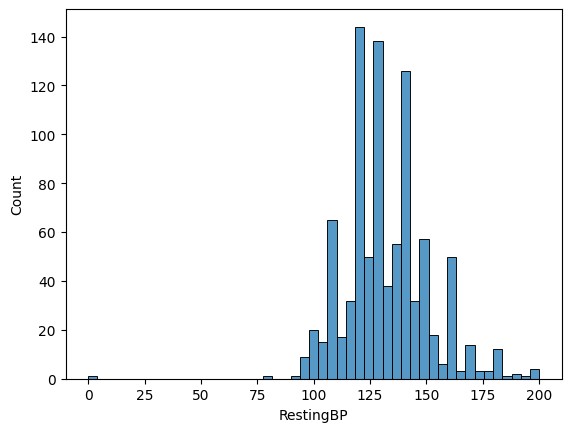

In [11]:
sns.histplot(data=df, x='RestingBP')

In [12]:
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)
df['Cholesterol'].fillna(df['Cholesterol'].mean(), inplace=True)

<Axes: xlabel='Cholesterol', ylabel='Count'>

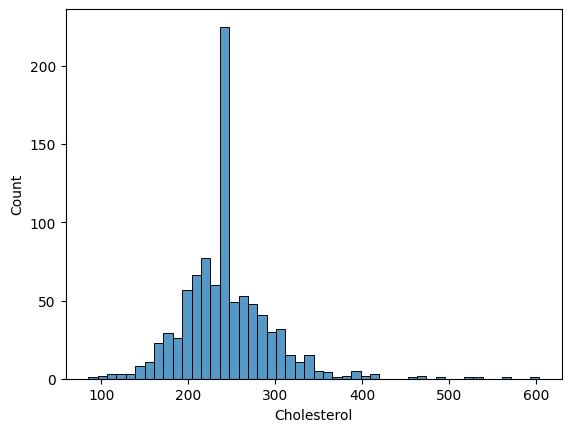

In [13]:
sns.histplot(data=df, x='Cholesterol')

In [14]:
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)
df['RestingBP'].fillna(df['RestingBP'].mean(), inplace=True)

<Axes: xlabel='RestingBP', ylabel='Count'>

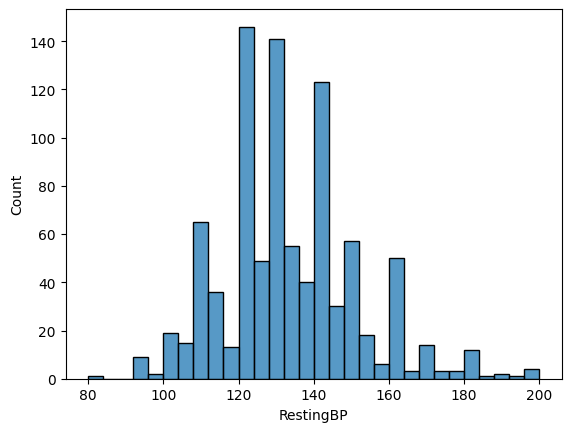

In [15]:
sns.histplot(data=df, x='RestingBP')

In [16]:
df = pd.get_dummies(df, columns=['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'], drop_first=True,dtype=int)

In [17]:
df.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='object')

<Axes: >

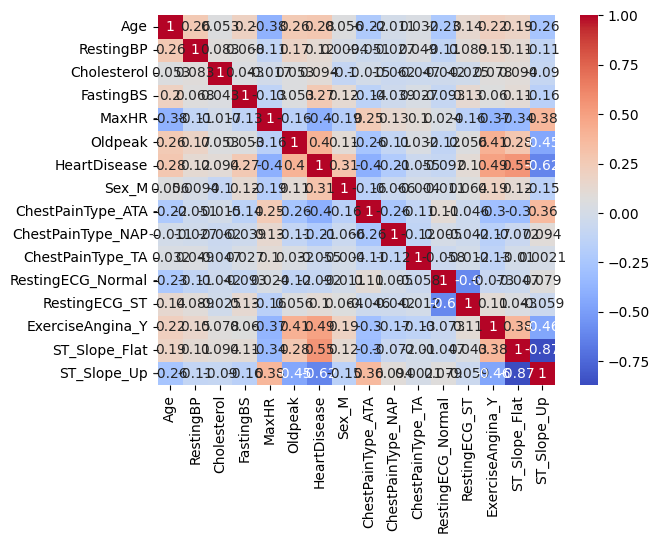

In [18]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score,precision_score, recall_score
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


In [20]:
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,stratify=y)

In [22]:
scaler = StandardScaler()   
x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(X_test)

In [23]:
model = LogisticRegression()
model.fit(x_train_scaled, y_train)
y_pred = model.predict(x_test_scaled)

In [24]:
import joblib

joblib.dump(model, "heart_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [25]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8913043478260869
Precision: 0.8942307692307693
Recall: 0.9117647058823529
F1 Score: 0.9029126213592233

Confusion Matrix:
[[71 11]
 [ 9 93]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.87      0.88        82
           1       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184



In [26]:
import joblib

model = joblib.load("heart_model.pkl")
scaler = joblib.load("scaler.pkl")

print("Model loaded:", type(model))
print("Scaler loaded:", type(scaler))

Model loaded: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Scaler loaded: <class 'sklearn.preprocessing._data.StandardScaler'>


In [27]:
print("Number of features:", model.n_features_in_)
print("Scaler expects:", scaler.n_features_in_)

Number of features: 15
Scaler expects: 15


In [29]:
print("MODEL FEATURES:")
for i, feature in enumerate(scaler.feature_names_in_, start=1):
    print(i, feature)

MODEL FEATURES:
1 Age
2 RestingBP
3 Cholesterol
4 FastingBS
5 MaxHR
6 Oldpeak
7 Sex_M
8 ChestPainType_ATA
9 ChestPainType_NAP
10 ChestPainType_TA
11 RestingECG_Normal
12 RestingECG_ST
13 ExerciseAngina_Y
14 ST_Slope_Flat
15 ST_Slope_Up


In [31]:
import pandas as pd

# Select one row from the test dataset
sample = X_test.iloc[[0]]

# Scale the sample using your saved scaler
sample_scaled = scaler.transform(sample)

# Predict using your saved Logistic Regression model
prediction = model.predict(sample_scaled)[0]

print("Input features:")
print(sample)

print("\nActual class:", y_test.iloc[0])
print("Predicted class:", prediction)

Input features:
     Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  Sex_M  \
356   46      115.0   244.635389          0    113      1.5      1   

     ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  \
356                  0                  0                 0   

     RestingECG_Normal  RestingECG_ST  ExerciseAngina_Y  ST_Slope_Flat  \
356                  1              0                 1              1   

     ST_Slope_Up  
356            0  

Actual class: 1
Predicted class: 1
